In [2]:
import numpy as np 
import pandas as pd 

In [3]:
df = pd.read_csv("anime.csv")

In [8]:
# 1. Make a new column for episode count
def extract_episodes(txt):
    check = False
    data = ""
    for i in txt:
        if i == ")":
            check = False
            return data
        if check == True: 
            data = data + i 
        if i == '(':
            check = True 

In [5]:
df["Episodes"] = df["Title"].apply(extract_episodes)

In [7]:
df.head(5) 

,Rank,Title,Score,Episodes
0,1,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,9.10,64 eps
1,2,"Steins;GateTV (24 eps)Apr 2011 - Sep 20112,473...",9.07,24 eps
2,3,Bleach: Sennen Kessen-henTV (13 eps)Oct 2022 -...,9.06,13 eps
3,4,"Gintama°TV (51 eps)Apr 2015 - Mar 2016605,113 ...",9.06,51 eps
4,5,Shingeki no Kyojin Season 3 Part 2TV (10 eps)A...,9.05,10 eps


In [9]:
# 2. Make a new column for time stamp
def extraction_time(txt):
    check = False
    data = ""
    for i in range(len(txt)):
        if txt[i] == ')':
            for j in range(i+1,i+20):
                data += txt[j]

            return data

In [10]:
df['Total Time'] = df['Title'].apply(extraction_time)
df.head(5) 

,Rank,Title,Score,Episodes,Total Time
0,1,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,9.10,64 eps,Apr 2009 - Jul 2010
1,2,"Steins;GateTV (24 eps)Apr 2011 - Sep 20112,473...",9.07,24 eps,Apr 2011 - Sep 2011
2,3,Bleach: Sennen Kessen-henTV (13 eps)Oct 2022 -...,9.06,13 eps,Oct 2022 - Dec 2022
3,4,"Gintama°TV (51 eps)Apr 2015 - Mar 2016605,113 ...",9.06,51 eps,Apr 2015 - Mar 2016
4,5,Shingeki no Kyojin Season 3 Part 2TV (10 eps)A...,9.05,10 eps,Apr 2019 - Jul 2019


In [11]:
# 3. Which anime has the highest score
df[df['Score'] == df['Score'].max()]

,Rank,Title,Score,Episodes,Total Time
0,1,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,9.1,64 eps,Apr 2009 - Jul 2010


In [12]:
# 4. Give me top 5 highest scoring anime
df.sort_values(by="Score", ascending=False).head(5)

,Rank,Title,Score,Episodes,Total Time
0,1,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,9.10,64 eps,Apr 2009 - Jul 2010
1,2,"Steins;GateTV (24 eps)Apr 2011 - Sep 20112,473...",9.07,24 eps,Apr 2011 - Sep 2011
2,3,Bleach: Sennen Kessen-henTV (13 eps)Oct 2022 -...,9.06,13 eps,Oct 2022 - Dec 2022
3,4,"Gintama°TV (51 eps)Apr 2015 - Mar 2016605,113 ...",9.06,51 eps,Apr 2015 - Mar 2016
4,5,Shingeki no Kyojin Season 3 Part 2TV (10 eps)A...,9.05,10 eps,Apr 2019 - Jul 2019


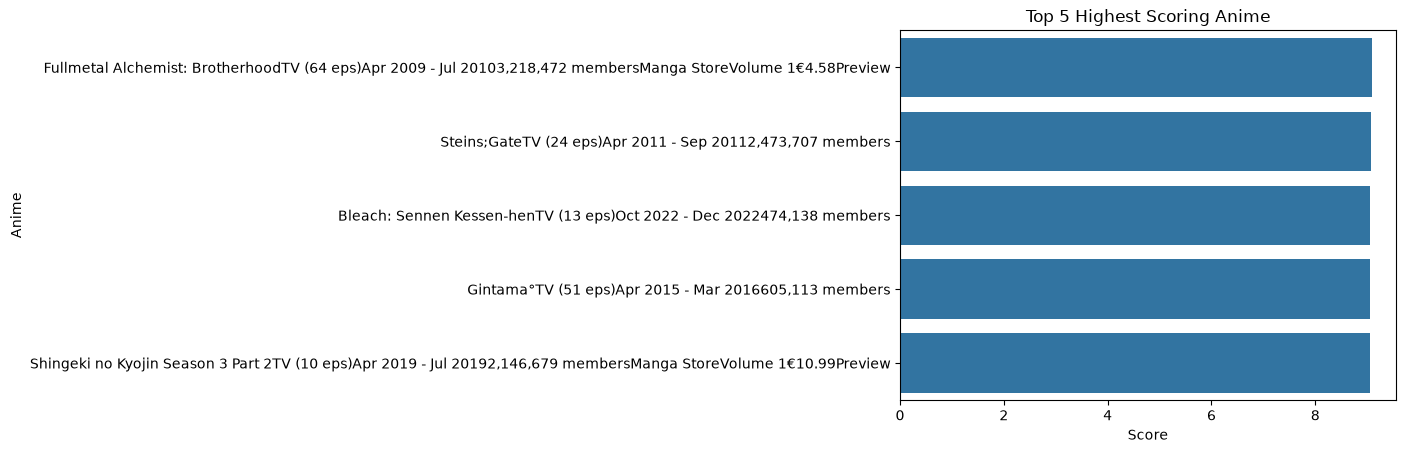

In [13]:
#5. Which anime has the highest episode count
import matplotlib.pyplot as plt
import seaborn as sns

top5 = df.sort_values(by="Score", ascending=False).head(5)

sns.barplot(data=top5, x="Score", y="Title")

plt.title("Top 5 Highest Scoring Anime")
plt.xlabel("Score")
plt.ylabel("Anime")
plt.show()


In [15]:
# 6. Animes with top 5 episode count
df.sort_values(by="Episodes", ascending=False).head(5)

,Rank,Title,Score,Episodes,Total Time
42,43,Hajime no IppoTV (75 eps)Oct 2000 - Mar 200255...,8.76,75 eps,Oct 2000 - Mar 2002
24,25,"MonsterTV (74 eps)Apr 2004 - Sep 20051,041,081...",8.87,74 eps,Apr 2004 - Sep 2005
22,23,Owarimonogatari 2nd SeasonTV (7 eps)Aug 2017 -...,8.88,7 eps,Aug 2017 - Aug 2017
0,1,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,9.10,64 eps,Apr 2009 - Jul 2010
3,4,"Gintama°TV (51 eps)Apr 2015 - Mar 2016605,113 ...",9.06,51 eps,Apr 2015 - Mar 2016


In [17]:
from dateutil.relativedelta import relativedelta
from datetime import datetime

def calculate_total_months(period):
    try:
        start_str, end_str = period.split(' - ')

        start_date = datetime.strptime(start_str, '%b %Y')
        end_date = datetime.strptime(end_str, '%b %Y')

        r = relativedelta(end_date, start_date) #This calculates the difference between the two dates.

        return r.years * 12 + r.months + 1

    except:
        return None

df['Months'] = df['Total Time'].apply(calculate_total_months)
df.head(2)

,Rank,Title,Score,Episodes,Total Time,Months
0,1,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,9.10,64 eps,Apr 2009 - Jul 2010,16
1,2,"Steins;GateTV (24 eps)Apr 2011 - Sep 20112,473...",9.07,24 eps,Apr 2011 - Sep 2011,6


In [18]:
# 7. Which is the longest running anime
df[df["Months"] == df["Months"].max()]

,Rank,Title,Score,Episodes,Total Time,Months
11,12,Ginga Eiyuu DensetsuOVA (110 eps)Jan 1988 - Ma...,9.02,110 eps,Jan 1988 - Mar 1997,111
